# Phase 5 — Full-Image Comparison of the Updated Models

Compare **bicubic**, the **continued MSE generator** selected at epoch 38, and the **second GAN** selected at epoch 3.

This repeat evaluation uses the same 50 DIV2K test images and full-image protocol as the first evaluation. It measures how the updated models compare on that benchmark. The notebook writes a separate report with the exact weight fingerprints.

Use the GPU runtime and the Drive folder from the earlier phases.


## 1. Update the project and install dependencies
An existing clean main checkout is updated with a fast-forward pull.


In [1]:
from pathlib import Path
import importlib
import json
import os
import subprocess
import sys

PROJECT_ROOT = Path("/content/SRGAN-Image-Super-Resolution")
REPO_URL = "https://github.com/ennaguiyoussef/SRGAN-Image-Super-Resolution.git"
if not PROJECT_ROOT.exists():
    subprocess.run(["git", "clone", "--branch", "main", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    if not (PROJECT_ROOT / ".git").is_dir():
        raise RuntimeError("Project folder exists but is not a Git checkout.")
    changes = subprocess.check_output(
        ["git", "-C", str(PROJECT_ROOT), "status", "--porcelain", "--untracked-files=no"],
        text=True,
    )
    if changes.strip():
        raise RuntimeError("Save local tracked edits before updating this checkout.")
    branch = subprocess.check_output(
        ["git", "-C", str(PROJECT_ROOT), "branch", "--show-current"], text=True
    ).strip()
    if branch != "main":
        raise RuntimeError("Select the main branch before running this notebook.")
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only", "origin", "main"], check=True)
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
importlib.invalidate_caches()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
print("Project checkout ready.")


Project checkout ready.


## 2. Restore the same test split and load the updated generators
The phase-2 manifest fixes the 50 test image IDs. The weights come from `pretrain_full_continue_v1/best_generator.pt` and `adversarial_full_v2/best_gan_generator.pt`.


In [2]:
import hashlib
import io
import torch
from google.colab import drive
from src.data import extract_hr_archive, split_manifest
from src.models import Generator
from src.setup import environment_report, load_config, prepare_directories

config = load_config(PROJECT_ROOT / "configs/srgan.yaml")
runtime = environment_report()
if not runtime["cuda_available"]:
    raise RuntimeError("Select a GPU runtime for full-image evaluation.")
device = torch.device("cuda:0")
print("GPU:", runtime["gpu"])

drive.mount("/content/drive")
output_root = Path("/content/drive/MyDrive/SRGAN-Image-Super-Resolution")
paths = prepare_directories(PROJECT_ROOT, output_root)
data_root = paths["data"] / "DIV2K"
manifest_path = output_root / "splits" / "div2k_seed42.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)
if manifest != split_manifest(config["seed"]):
    raise ValueError("Saved split differs from the phase-2 manifest.")
test_names = sorted(manifest["test"])
if len(test_names) != 50:
    raise ValueError("Expected 50 held-out test images.")
missing = [name for name in test_names if not (data_root / name).is_file()]
if missing:
    archive = output_root / "dataset_cache" / "DIV2K_valid_HR.zip"
    if not archive.is_file():
        raise FileNotFoundError("Restore the phase-2 validation HR archive on Drive.")
    extract_hr_archive(archive, data_root, "DIV2K_valid_HR", [int(Path(name).stem) for name in missing])

weights_paths = {
    "pretrained": paths["checkpoints"] / "pretrain_full_continue_v1" / "best_generator.pt",
    "gan": paths["checkpoints"] / "adversarial_full_v2" / "best_gan_generator.pt",
}
models, weights_info = {}, {}
for name, path in weights_paths.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {name} weights: {path}. Run the corresponding training notebook.")
    payload = path.read_bytes()
    model = Generator()
    model.load_state_dict(torch.load(io.BytesIO(payload), map_location="cpu", weights_only=True))
    models[name] = model.to(device).eval()
    weights_info[name] = {"path": str(path), "sha256": hashlib.sha256(payload).hexdigest()}
    print(f"{name} weights loaded from {path.parent.name}/{path.name}")

RESULTS_DIR = paths["results"] / "final_test_evaluation_v2"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Held-out images ready:", len(test_names))


GPU: Tesla T4
Mounted at /content/drive
pretrained weights loaded from pretrain_full_continue_v1/best_generator.pt
gan weights loaded from adversarial_full_v2/best_gan_generator.pt
Held-out images ready: 50


## 3. Score the full images
1. Trim the bottom and right edges of HR to multiples of four.
2. Downsample HR with Pillow bicubic. Use this exact LR image for all three methods.
3. Reconstruct at ×4 and score against the trimmed HR image.

The generator uses 192-pixel LR tiles with a 48-pixel LR halo. The halo gives context and is discarded when stitching the tile outputs. Scores use RGB float pixels in [0, 1], exclude four HR pixels at each edge, and average the per-image results. SSIM uses a 7×7 window and averages RGB channels. PSNR is capped at 120 dB for exact matches.

This protocol evaluates full images. Phase-4 scores used validation center crops, so compare methods within this test table.


In [3]:
import time
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
from src.evaluation import SCALE, image_metrics, make_test_pair, resolve_image, rgb_array

TILE_SIZE = 192
HALO = 48
BORDER = 4
method_names = ("bicubic", "pretrained", "gan")
rows, previews = [], []
started = time.perf_counter()
for index, name in enumerate(tqdm(test_names, desc="Full-image evaluation"), start=1):
    with Image.open(data_root / name) as image:
        lr, hr = make_test_pair(image)
    reference = rgb_array(hr)
    predictions = {"bicubic": rgb_array(lr.resize(hr.size, Image.Resampling.BICUBIC))}
    for method, model in models.items():
        predictions[method] = resolve_image(model, lr, tile_size=TILE_SIZE, halo=HALO)

    for method in method_names:
        rows.append({
            "image": Path(name).name, "method": method,
            "lr_width": lr.width, "lr_height": lr.height,
            "hr_width": hr.width, "hr_height": hr.height,
            **image_metrics(reference, predictions[method], border=BORDER),
        })

    if index <= 3:
        # Select an aligned center region for display only.
        size = min(48, lr.width, lr.height)
        x, y = (lr.width - size) // 2, (lr.height - size) // 2
        area = np.s_[y * SCALE:(y + size) * SCALE, x * SCALE:(x + size) * SCALE]
        previews.append((
            Path(name).stem, lr.crop((x, y, x + size, y + size)),
            [predictions[method][area].copy() for method in method_names],
            reference[area].copy(),
        ))
    if index == 1:
        print(f"First image scored in {time.perf_counter() - started:.1f} seconds.")

elapsed_seconds = time.perf_counter() - started
print(f"Scored {len(test_names)} images in {elapsed_seconds / 60:.1f} minutes.")


Full-image evaluation:   0%|          | 0/50 [00:00<?, ?it/s]

First image scored in 9.0 seconds.
Scored 50 images in 3.9 minutes.


## 4. Compare test scores and visual details
The first three images in sorted test-ID order supply the preview. Each row shows the same aligned region from LR, bicubic, continued G, second GAN, and HR. Look at edges, small textures, and any changes in color.


Method         Images   PSNR (dB)       SSIM
bicubic            50      26.491    0.76055
pretrained         50      26.553    0.76641
gan                50      26.254    0.74091


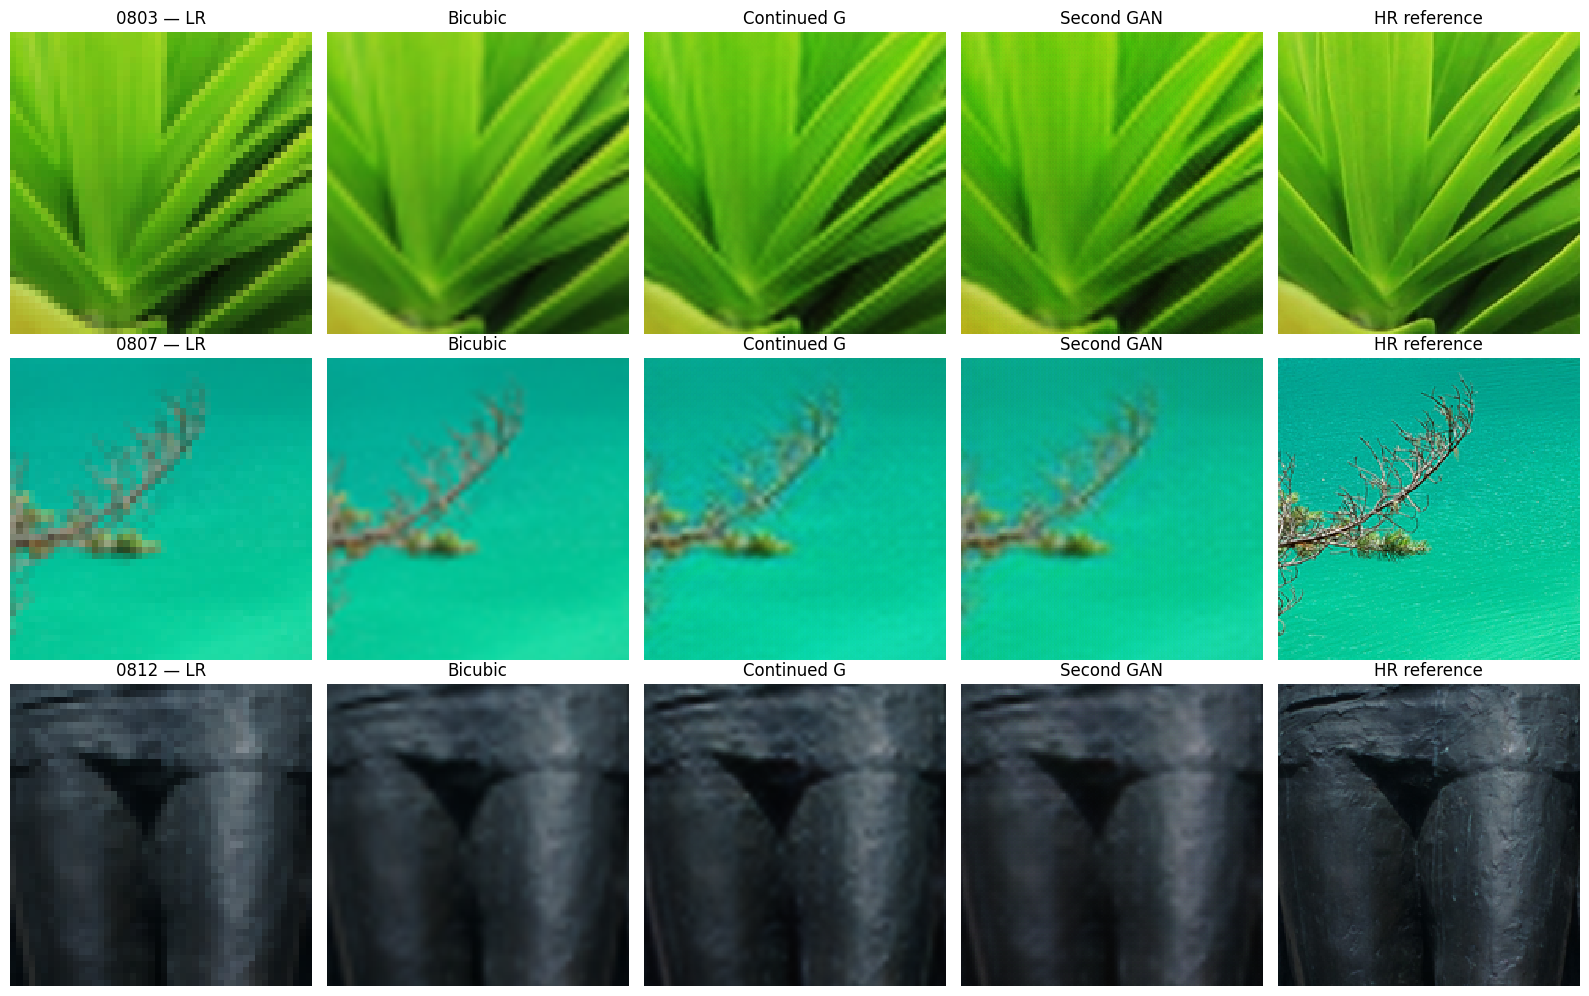

In [7]:
import matplotlib.pyplot as plt

summary = []
for method in method_names:
    scores = [row for row in rows if row["method"] == method]
    summary.append({
        "method": method, "images": len(scores),
        "mean_psnr_db": float(np.mean([row["psnr_db"] for row in scores])),
        "mean_ssim": float(np.mean([row["ssim"] for row in scores])),
    })
print(f"{'Method':<14} {'Images':>6} {'PSNR (dB)':>11} {'SSIM':>10}")
for row in summary:
    print(f"{row['method']:<14} {row['images']:>6} {row['mean_psnr_db']:>11.3f} {row['mean_ssim']:>10.5f}")

fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for row, (image_id, lr_crop, sr_crops, hr_crop) in enumerate(previews):
    labels = [f"{image_id} — LR", "Bicubic", "Continued G", "Second GAN", "HR reference"]
    for col, (pixels, label) in enumerate(zip([lr_crop, *sr_crops, hr_crop], labels)):
        axes[row, col].imshow(pixels, interpolation="nearest")
        axes[row, col].set_title(label)
        axes[row, col].axis("off")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "test_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Save the evaluation
The CSVs contain per-image scores and method means. The JSON records the test IDs, protocol, and exact weights fingerprints.


In [8]:
import csv
from src.pretrain import atomic_json_save

for filename, records in [("per_image_metrics.csv", rows), ("summary_metrics.csv", summary)]:
    path = RESULTS_DIR / filename
    temporary = path.with_suffix(".csv.tmp")
    try:
        with temporary.open("w", newline="", encoding="utf-8") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(records[0]))
            writer.writeheader()
            writer.writerows(records)
        temporary.replace(path)
    finally:
        temporary.unlink(missing_ok=True)

report = {
    "git_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip(),
    "evaluation_round": "updated_models_same_test_split",
    "runtime": runtime, "weights": weights_info, "test_images": test_names,
    "manifest_sha256": hashlib.sha256(manifest_bytes).hexdigest(),
    "scale_factor": SCALE, "image_protocol": "full RGB, right/bottom trim to multiples of 4",
    "degradation": "Pillow bicubic downsampling from full HR",
    "border_shave_hr_pixels": BORDER, "pixel_data_range": 1.0,
    "psnr_mse_floor": 1e-12, "ssim_window": 7, "ssim_gaussian_weights": False,
    "ssim_use_sample_covariance": True, "averaging": "unweighted mean over images",
    "tile_size_lr": TILE_SIZE, "halo_lr": HALO, "elapsed_seconds": elapsed_seconds,
    "summary": summary,
}
atomic_json_save(report, RESULTS_DIR / "test_report.json")
print("Phase 5 repeat complete. Updated full-image metrics and comparisons saved.")
print("Results:", RESULTS_DIR)


Phase 5 repeat complete. Updated full-image metrics and comparisons saved.
Results: /content/drive/MyDrive/SRGAN-Image-Super-Resolution/results/final_test_evaluation_v2


## 6. Optional: upscale your own LR image
Set `CUSTOM_LR_PATH` to an image in Drive and choose `"gan"` or `"pretrained"`. The output is a PNG at four times the input width and height.


In [9]:
from PIL import ImageOps

CUSTOM_LR_PATH = None  # Example: "/content/drive/MyDrive/input.png"
CUSTOM_MODEL = "gan"

if CUSTOM_LR_PATH is not None:
    input_path = Path(CUSTOM_LR_PATH)
    with Image.open(input_path) as image:
        lr = ImageOps.exif_transpose(image).convert("RGB")
    pixels = resolve_image(models[CUSTOM_MODEL], lr, tile_size=TILE_SIZE, halo=HALO)
    sr = Image.fromarray(np.rint(pixels * 255).astype(np.uint8))
    path = RESULTS_DIR / f"{input_path.stem}_{CUSTOM_MODEL}_x4.png"
    sr.save(path)
    print(f"Upscaled {lr.width}×{lr.height} to {sr.width}×{sr.height}.")
    print("Saved:", path)
